# Feature D — Price Tier Classification

**Goal:** predict whether a product is `budget`, `mid_range`, or `premium` using title, description, bullets, brand, category, rating, review count, and other non-price attributes.

**Leakage rule:** price, list price, discount, currency, and every price-derived field are excluded from model inputs. Observed price is used only to construct ground-truth labels and evaluate the classifier.

**Tier definition:** tiers are relative to each `search_keyword + detected currency` group. This is more meaningful than global cutoffs across unrelated products and avoids comparing USD amounts numerically with SEK amounts.

## 1. Google Colab setup

Change only `PROJECT` if your Drive folder has a different name. Keep this as the only project-path setup cell.

In [1]:
!pip install -q pandas pyarrow scikit-learn matplotlib seaborn joblib

In [2]:
from pathlib import Path
import sys

from google.colab import drive
drive.mount('/content/drive')

PROJECT = Path('/content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence')
assert PROJECT.exists(), f'Project folder not found: {PROJECT}'
sys.path.insert(0, str(PROJECT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay, f1_score

from analysis.price_tiers import (
    TIER_ORDER, apply_tier_rules, choose_search, compare_models,
    evaluate, fit_tier_rules, load_products, make_pipeline,
    missingness_table, model_frame, prepare_products,
    refit_for_deployment, save_artifacts, split_for_evaluation,
    top_linear_features, tune_linear_candidates,
)

sns.set_theme(style='whitegrid')
OUTPUT_DIR = PROJECT / 'data' / 'models' / 'PriceTierClassification'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Project:', PROJECT)
print('Output:', OUTPUT_DIR)

Mounted at /content/drive
Project: /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence
Output: /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence/data/models/PriceTierClassification


## 2. Read and show the original product data

The original table is displayed before any filtering or transformation, so the cleaning decisions can be checked against the source data.

In [3]:
DATA_PATH = PROJECT / 'data' / 'products.csv'
raw = load_products(DATA_PATH)
print('Original shape:', raw.shape)
print('Columns:', raw.columns.tolist())
display(raw)

Original shape: (859, 31)
Columns: ['asin', 'product_url', 'search_keyword', 'search_keywords', 'search_rank', 'sponsored', 'collected_at', 'title', 'brand', 'bullets', 'description', 'category_breadcrumb', 'price', 'price_raw', 'currency', 'list_price', 'discount_pct', 'availability', 'price_status', 'rating', 'review_count', 'image_url', 'image_url_sized', 'has_video', 'video_url', 'video_page_url', 'reviews', 'reviews_collected', 'product_url_status', 'image_url_status', 'video_url_status']


,asin,product_url,search_keyword,search_keywords,search_rank,sponsored,collected_at,title,brand,bullets,...,image_url,image_url_sized,has_video,video_url,video_page_url,reviews,reviews_collected,product_url_status,image_url_status,video_url_status
0,B0H9LHWBDK,https://www.amazon.com/dp/B0H9LHWBDK,wireless earbuds,"[""wireless earbuds""]",1,False,2026-08-27T18:16:41+00:00,"Wireless Earbuds, 2026 Bluetooth 5.4 Headphone...",XIAOWTEK,"[""LED Power Display and 50H Playback: Dual dig...",...,https://m.media-amazon.com/images/I/61odQgshCW...,https://m.media-amazon.com/images/I/61odQgshCW...,True,https://m.media-amazon.com/images/S/al-na-9d57...,https://www.amazon.com/dp/B0H9LHWBDK,"[{""reviewer_name"": ""diamela"", ""rating"": 5.0, ""...",13,ok,ok,ok
1,B0HBWW3958,https://www.amazon.com/dp/B0HBWW3958,wireless earbuds,"[""wireless earbuds""]",2,False,2026-08-27T18:16:59+00:00,"Wireless Earbuds, Bluetooth 5.3 Headphones HiF...",Fhumsh,"[""Smart LED Display & 50H Sport Headphones: Th...",...,https://m.media-amazon.com/images/I/61D5ZCSIym...,https://m.media-amazon.com/images/I/61D5ZCSIym...,True,https://m.media-amazon.com/images/S/al-na-9d57...,https://www.amazon.com/dp/B0HBWW3958,"[{""reviewer_name"": ""Mary Santana"", ""rating"": 5...",13,ok,ok,ok
2,B0H3NTRWCL,https://www.amazon.com/dp/B0H3NTRWCL,wireless earbuds,"[""wireless earbuds""]",3,False,2026-08-27T18:17:15+00:00,"AI Translation Earbuds Real Time, 134 Language...",Tiksounds,"[""Real-Time AI Translation: AI translation ear...",...,https://m.media-amazon.com/images/I/71MUqRYV7B...,https://m.media-amazon.com/images/I/71MUqRYV7B...,False,NaN,https://www.amazon.com/dp/B0H3NTRWCL,"[{""reviewer_name"": ""Cathy"", ""rating"": 5.0, ""ti...",9,ok,ok,none
3,B0H7R1LD7B,https://www.amazon.com/dp/B0H7R1LD7B,wireless earbuds,"[""wireless earbuds""]",4,False,2026-08-27T18:17:34+00:00,"HAOYUYAN Wireless Earbuds, Sports Bluetooth He...",HAOYUYAN,"[""【Sports Comfort & IPX7 Waterproof】BX17 Wirel...",...,https://m.media-amazon.com/images/I/71cmAChhQK...,https://m.media-amazon.com/images/I/71cmAChhQK...,True,https://m.media-amazon.com/images/S/al-na-9d57...,https://www.amazon.com/dp/B0H7R1LD7B,"[{""reviewer_name"": ""Amazon Customer"", ""rating""...",13,ok,ok,ok
4,B0G7H6K1WN,https://www.amazon.com/dp/B0G7H6K1WN,wireless earbuds,"[""wireless earbuds""]",5,False,2026-08-27T18:17:52+00:00,"Wireless Earbuds,Bluetooth 5.4 Ear buds,Sport ...",KTGEE,"[""Secure & Comfortable Earhook Fit – Flexible,...",...,https://m.media-amazon.com/images/I/71eD2UACLw...,https://m.media-amazon.com/images/I/71eD2UACLw...,True,https://m.media-amazon.com/images/S/al-na-9d57...,https://www.amazon.com/dp/B0G7H6K1WN,"[{""reviewer_name"": ""Maggie Martin"", ""rating"": ...",8,ok,ok,ok
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
854,B07R4JQFBC,https://www.amazon.com/dp/B07R4JQFBC,yamaha accoustic guitar,"[""yamaha accoustic guitar""]",44,False,2026-08-27T23:16:55+00:00,Yamaha Red Label FGX3 - Natural,Yamaha,"[""6-string Acoustic-electric Guitar with a Sol...",...,https://m.media-amazon.com/images/I/61ea3-zMpr...,https://m.media-amazon.com/images/I/61ea3-zMpr...,False,NaN,https://www.amazon.com/dp/B07R4JQFBC,"[{""reviewer_name"": ""Larry Robinson"", ""rating"":...",2,ok,ok,none
855,B0FX9C1ZDH,https://www.amazon.com/dp/B0FX9C1ZDH,yamaha accoustic guitar,"[""yamaha accoustic guitar""]",45,False,2026-08-27T23:17:14+00:00,Enya NOVA GO SP1 Carbon Fiber 35-Inch Smart Ac...,enya,"[""WHY CARBON FIBER - Nova Go SP1 is made of ca...",...,https://m.media-amazon.com/images/I/71Ncc8mgnk...,https://m.media-amazon.com/images/I/71Ncc8mgnk...,True,https://m.media-amazon.com/images/S/al-na-9d57...,https://www.amazon.com/dp/B0FX9C1ZDH,"[{""reviewer_name"": ""RJ"", ""rating"": 5.0, ""title...",8,ok,ok,ok
856,B083JPF63Y,https://www.amazon.com/dp/B083JPF63Y,yamaha accoustic guitar,"[""yamaha accoustic guitar""]",46,False,2026-08-27T23:17:33+00:00,Yamaha NTX1 BL Cutaway Acoustic-Electric Nylon...,Yamaha,"[""Mod

## 3. Missing-value audit and preprocessing

| Situation | Action | Reason |
|---|---|---|
| Missing price | Exclude from supervised labels, retain for final prediction | A target must never be invented or median-imputed |
| Currency missing but `price_raw` contains USD/SEK | Recover the currency prefix | Prevent mixed-currency labels |
| Currency still unknown | Exclude from label construction | A numeric amount without currency is not comparable |
| Missing title/description/bullets | Replace with empty text inside preparation | TF-IDF requires text; absence carries no invented content |
| Missing brand/category/availability | Impute `__MISSING__` inside each fitted pipeline | Keeps rows and prevents train/test leakage |
| Missing rating/review count/rank | Median-impute using training folds and add missing indicators | Retains rows while letting the model learn that a value was absent |
| Invalid rating/count/price | Convert to missing | Invalid numeric values should not influence labels or features |
| Duplicate ASIN | Keep the latest row | Prevent the same product appearing in train and test |
| Explicit price strings in text | Remove currency-price expressions | Prevent label leakage from title/description/bullets |

,missing_count,missing_percent
currency,170,19.790454
price,73,8.498254
availability,41,4.772992
brand,29,3.376019
review_count,3,0.349243
description,2,0.232829
category_breadcrumb,1,0.116414
title,0,0.000000
search_keyword,0,0.000000
rating,0,0.000000


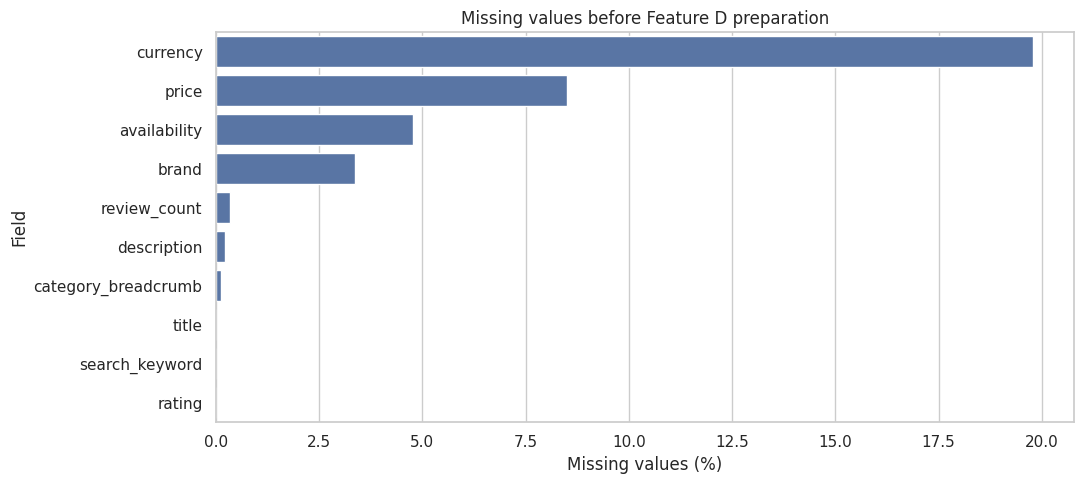

In [4]:
missing_before = missingness_table(raw)
display(missing_before)

plt.figure(figsize=(11, 5))
sns.barplot(data=missing_before.reset_index(), x='missing_percent', y='index', color='#4C72B0')
plt.xlabel('Missing values (%)'); plt.ylabel('Field')
plt.title('Missing values before Feature D preparation')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'missing_values_before.png', dpi=160, bbox_inches='tight')
plt.show()

In [5]:
prepared, audit = prepare_products(raw)
display(pd.Series(audit, name='value').to_frame())
display(prepared[[
    'asin', 'search_keyword', 'title', 'brand', 'price_numeric',
    'label_currency', 'rating', 'log_review_count', 'label_eligible'
]])

print('Currency recovered from currency/price_raw:')
display(prepared['label_currency'].value_counts(dropna=False).rename('products').to_frame())

assert prepared['asin'].is_unique
assert prepared.loc[prepared['label_eligible'], 'price_numeric'].notna().all()

,value
original_rows,859
prepared_rows,859
duplicate_asins_removed,0
missing_price_rows,73
unknown_currency_rows,73
label_eligible_rows,786


,asin,search_keyword,title,brand,price_numeric,label_currency,rating,log_review_count,label_eligible
0,B0H9LHWBDK,wireless earbuds,"Wireless Earbuds, 2026 Bluetooth 5.4 Headphone...",XIAOWTEK,190.39,SEK,4.6,6.634633,True
1,B0HBWW3958,wireless earbuds,"Wireless Earbuds, Bluetooth 5.3 Headphones HiF...",Fhumsh,190.30,SEK,5.0,5.283204,True
2,B0H3NTRWCL,wireless earbuds,"AI Translation Earbuds Real Time, 134 Language...",Tiksounds,190.39,SEK,5.0,3.332205,True
3,B0H7R1LD7B,wireless earbuds,"HAOYUYAN Wireless Earbuds, Sports Bluetooth He...",HAOYUYAN,228.40,SEK,4.6,5.840642,True
4,B0G7H6K1WN,wireless earbuds,"Wireless Earbuds,Bluetooth 5.4 Ear buds,Sport ...",KTGEE,161.82,SEK,4.7,5.846439,True
...,...,...,...,...,...,...,...,...,...
854,B07R4JQFBC,yamaha accoustic guitar,Yamaha Red Label FGX3 - Natural,Yamaha,1199.99,USD,4.5,1.945910,True
855,B0FX9C1ZDH,yamaha accoustic guitar,Enya NOVA GO SP1 Carbon Fiber 35-Inch Smart Ac...,enya,223.97,USD,4.5,5.225747,True
856,B083JPF63Y,yamaha accoustic guitar,Yamaha NTX1 BL Cutaway Acoustic-Electric Nylon...,Yamaha,549.99,USD,4.4,4.060443,True
857,B0CSM2MJ55,yamaha accoustic guitar,Fender FA-25N 3/4 Nylon String Acoustic Guitar...,Fender,125.99,USD,4.4,5.932245,True


Currency recovered from currency/price_raw:


,products
label_currency,
USD,689
SEK,97
<NA>,73


### Interpretation of preprocessing

Products without an observed price remain valuable prediction cases, but they cannot provide ground truth. Currency is recovered only for label construction and is not supplied to the classifier. All imputers used by the model live inside scikit-learn pipelines, so their statistics are learned from training folds rather than the full dataset.

## 4. Construct price-tier labels without test leakage

First split label-eligible products while preserving each category/currency group. Then learn the lower and upper cutoffs from **training prices only**. Cutoffs are the 33rd and 67th percentiles of distinct observed price points, so identical prices always receive identical tiers.

In [6]:
train, test = split_for_evaluation(prepared, test_size=0.20)
tier_rules = fit_tier_rules(train)
train['price_tier'] = apply_tier_rules(train, tier_rules)
test['price_tier'] = apply_tier_rules(test, tier_rules)

assert train['price_tier'].notna().all()
assert test['price_tier'].notna().all()
assert set(train['asin']).isdisjoint(set(test['asin']))

print('Training rows:', len(train), '| Test rows:', len(test))
display(tier_rules)
display(pd.DataFrame({
    'train': train['price_tier'].value_counts(),
    'test': test['price_tier'].value_counts(),
}).reindex(TIER_ORDER))

Training rows: 628 | Test rows: 158


,search_keyword,label_currency,budget_upper,mid_range_upper,training_rows,distinct_prices
0,DSLR camera,USD,457.736667,635.436667,12,12
1,USB-C hub,SEK,149.056667,295.163333,13,12
2,air purifier,USD,28.990000,102.990000,10,10
3,backpack,USD,27.170000,35.996667,11,11
4,bluetooth speaker,USD,29.976667,86.650000,11,11
5,budget laptop,USD,229.990000,250.910000,10,9
6,candle,USD,19.706667,25.333333,35,33
7,coffee maker,USD,43.330000,91.616667,26,23
8,desk lamp LED,USD,20.516667,32.656667,38,27
9,electric toothbrush,USD,24.810000,93.323333,34,21


,train,test
price_tier,,
budget,217,56
mid_range,217,55
premium,194,47


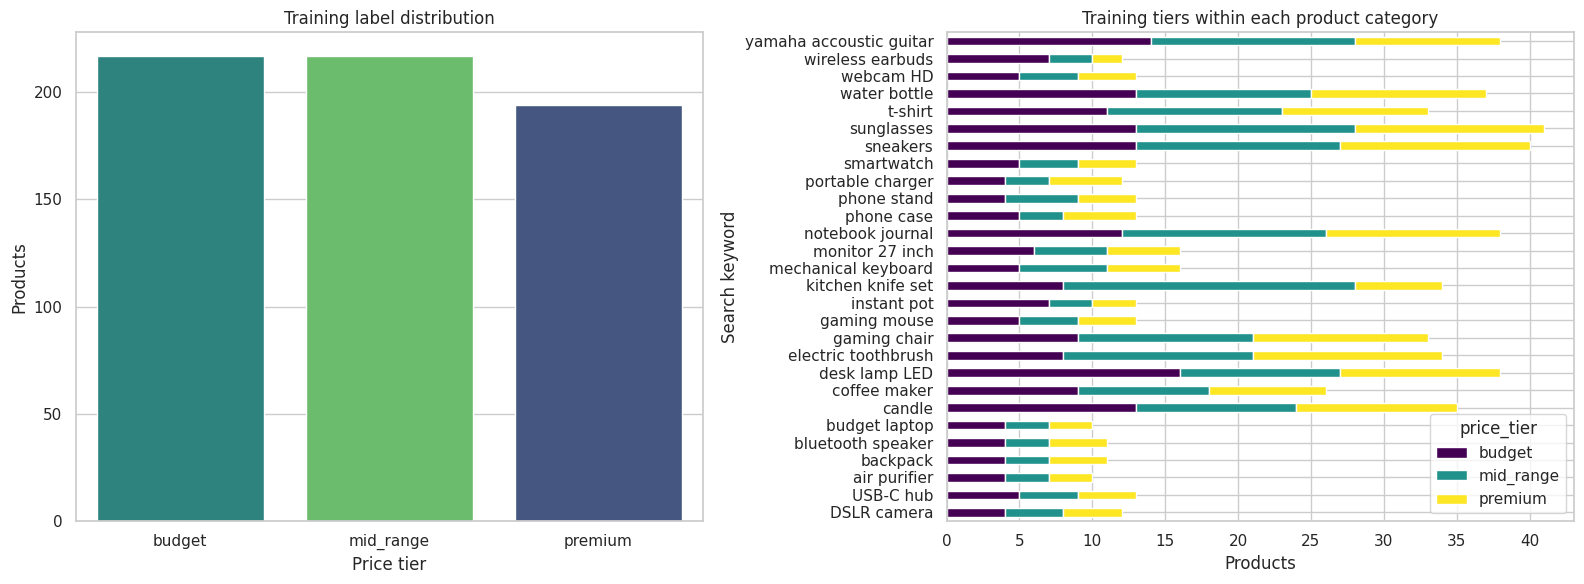

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
order = TIER_ORDER
sns.countplot(data=train, x='price_tier', order=order, ax=axes[0], palette='viridis', hue='price_tier', legend=False)
axes[0].set_title('Training label distribution')
axes[0].set_xlabel('Price tier'); axes[0].set_ylabel('Products')

category_tiers = pd.crosstab(train['search_keyword'], train['price_tier']).reindex(columns=order, fill_value=0)
category_tiers.plot(kind='barh', stacked=True, ax=axes[1], colormap='viridis')
axes[1].set_title('Training tiers within each product category')
axes[1].set_xlabel('Products'); axes[1].set_ylabel('Search keyword')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'tier_label_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

### Label interpretation

`budget`, `mid_range`, and `premium` mean lower, middle, and upper price positions among visually/semantically comparable products in the same search category and currency. They do not mean one global dollar threshold. This definition is suitable for a dataset containing cameras, notebooks, clothing, electronics, USD prices, and SEK prices.

## 4.1 EDA: patterns, relationships, and useful attributes

The following analysis uses the training partition only. This prevents the held-out test labels from influencing feature decisions. We examine how non-price numeric attributes vary by tier, whether useful attributes are skewed or missing, and which attributes have an ordinal relationship with the target.

rating                  log_review_count                      \
            count median      mean            count    median      mean   
price_tier                                                                
budget        217    4.5  4.456682              217  7.719574  7.541324   
mid_range     217    4.5  4.513825              217  7.871693  7.823154   
premium       194    4.5  4.485052              191  7.402452  7.355779   

           search_rank                   title_word_count                    \
                 count median       mean            count median       mean   
price_tier                                                                    
budget             217   14.0  18.451613              217   13.0  17.299539   
mid_range          217   15.0  19.635945              217   12.0  15.101382   
premium            194   18.0  23.257732              194   11.0  14.118557   

           description_word_count                    bullets_word_count  \
                            count median        mean              count   
price_tier                                                                
budget                        217   87.0  122.405530                217   
mid_range                     217   90.0  126.783410                217   
premium                       194   99.0  150.041237                194   

                               
           median        mean  
price_tier                     
budget      184.0  178.576037  
mid_range   148.0  160.442396  
premium     174.0  167.010309

,missing_percent,unique_values
brand,3.662420,334
availability,3.184713,29
log_review_count,0.477707,555
category_breadcrumb,0.159236,109
rating,0.000000,16
description_word_count,0.000000,271
title_word_count,0.000000,33
search_rank,0.000000,54
bullets_word_count,0.000000,275


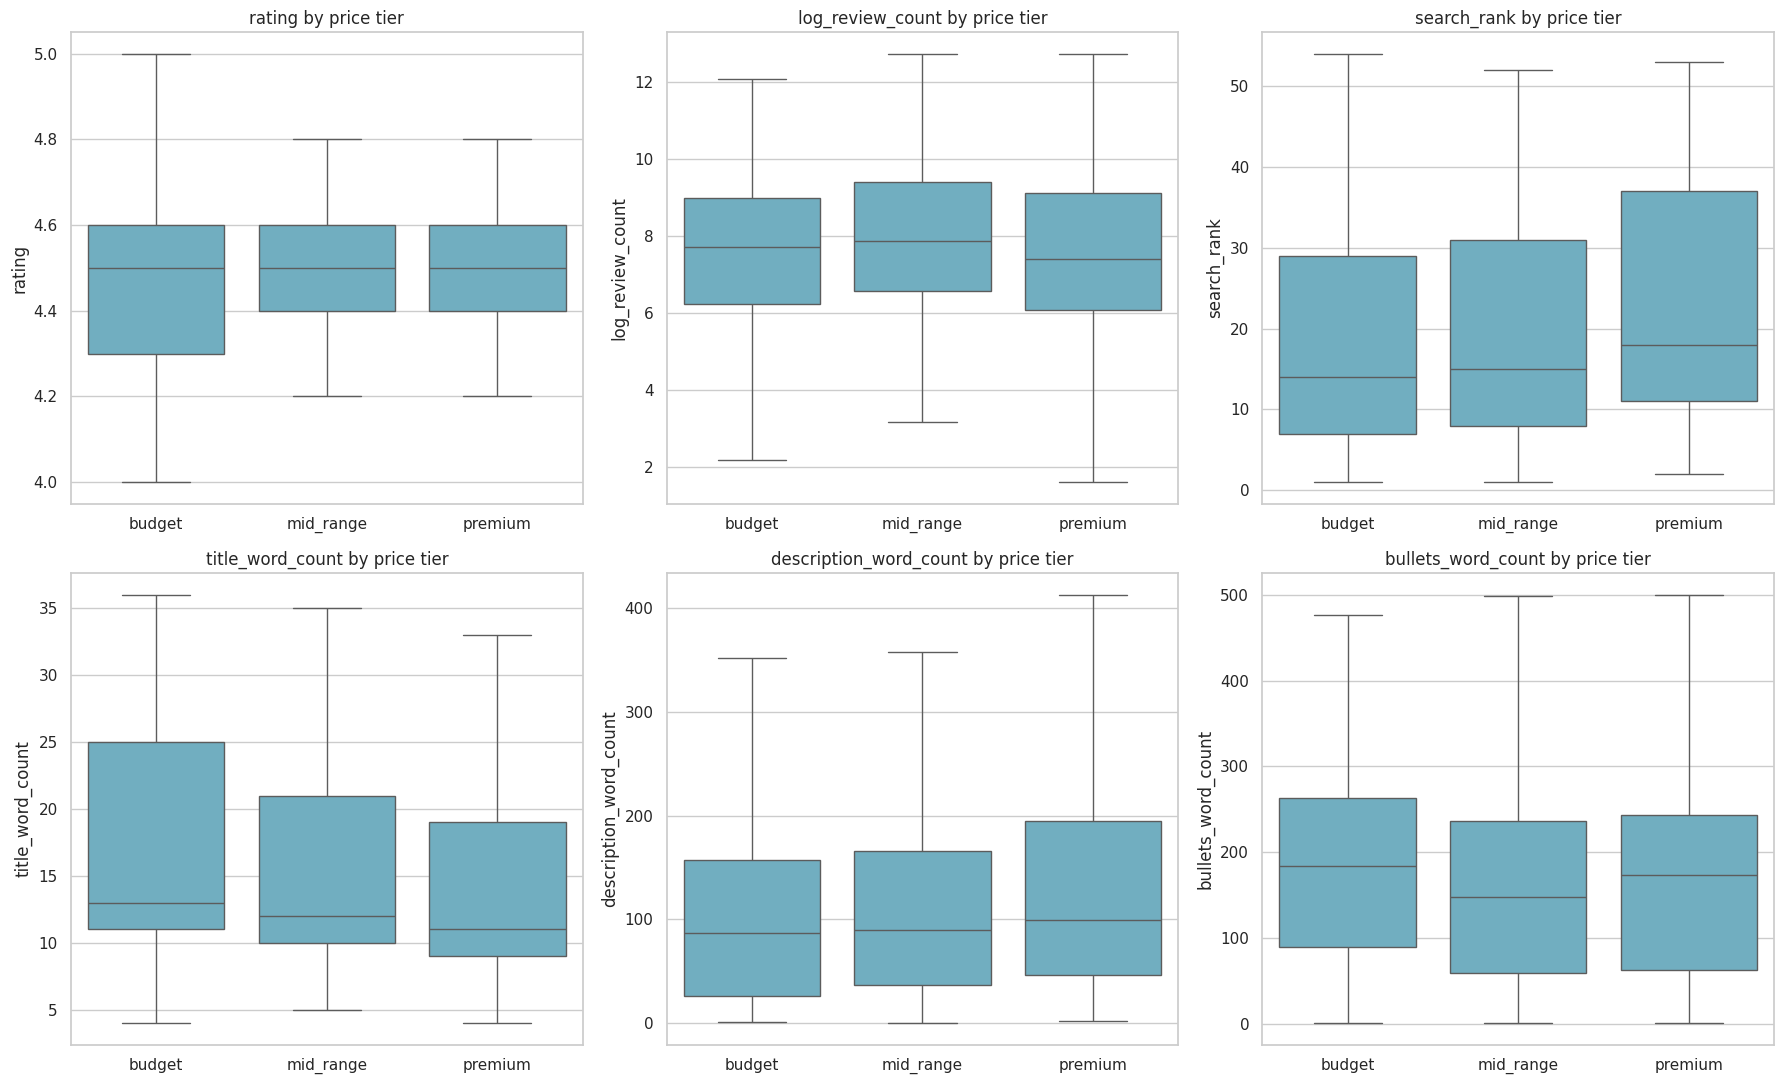

In [8]:
numeric_eda = [
    'rating', 'log_review_count', 'search_rank',
    'title_word_count', 'description_word_count', 'bullets_word_count',
]

# Tables make exact relationships visible; medians are robust to large outliers.
tier_numeric_summary = train.groupby('price_tier', observed=False)[numeric_eda].agg(['count', 'median', 'mean'])
display(tier_numeric_summary.reindex(TIER_ORDER))

attribute_quality = pd.DataFrame({
    'missing_percent': train[numeric_eda + ['brand', 'category_breadcrumb', 'availability']].isna().mean() * 100,
    'unique_values': train[numeric_eda + ['brand', 'category_breadcrumb', 'availability']].nunique(dropna=True),
}).sort_values('missing_percent', ascending=False)
display(attribute_quality)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for column, axis in zip(numeric_eda, axes.flat):
    sns.boxplot(data=train, x='price_tier', y=column, order=TIER_ORDER, showfliers=False, ax=axis, color='#64B5CD')
    axis.set_title(f'{column} by price tier')
    axis.set_xlabel('')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'attribute_relationships_by_tier.png', dpi=160, bbox_inches='tight')
plt.show()

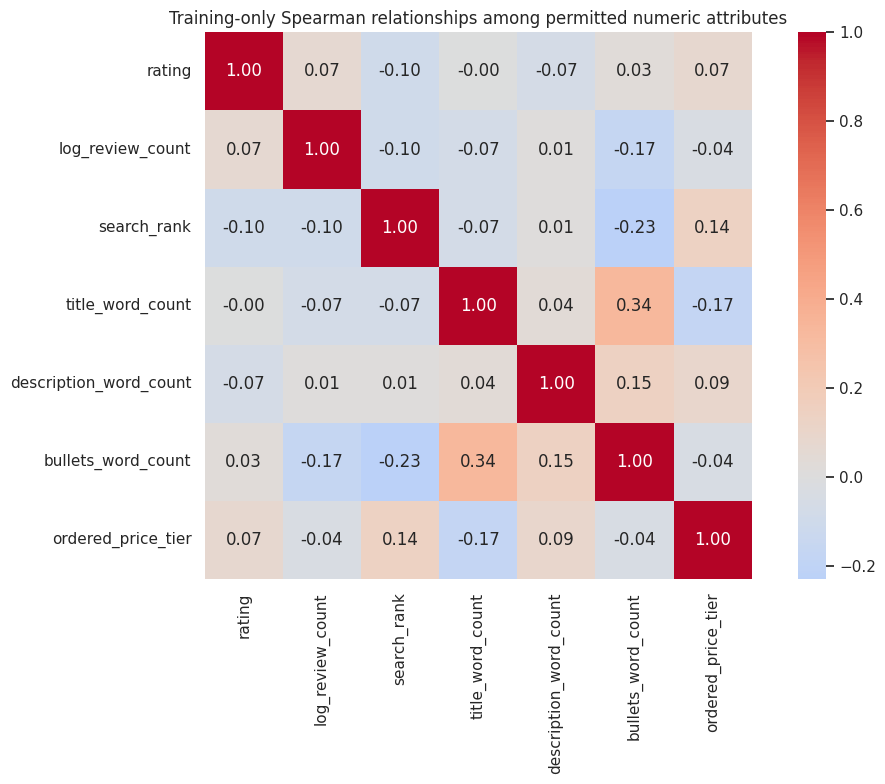

Absolute ordinal relationship with price tier (descriptive, not causal):


,absolute_spearman
title_word_count,0.172901
search_rank,0.138853
description_word_count,0.089895
rating,0.073973
bullets_word_count,0.044297
log_review_count,0.037029


In [9]:
# Spearman correlation is appropriate for ordered tiers and skewed count/rank variables.
tier_number = train['price_tier'].map({'budget': 0, 'mid_range': 1, 'premium': 2}).astype(float)
correlation_data = train[numeric_eda].copy()
correlation_data['ordered_price_tier'] = tier_number
spearman = correlation_data.corr(method='spearman')

plt.figure(figsize=(11, 8))
sns.heatmap(spearman, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Training-only Spearman relationships among permitted numeric attributes')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'numeric_relationship_heatmap.png', dpi=160, bbox_inches='tight')
plt.show()

target_relationship = spearman['ordered_price_tier'].drop('ordered_price_tier').abs().sort_values(ascending=False)
print('Absolute ordinal relationship with price tier (descriptive, not causal):')
display(target_relationship.rename('absolute_spearman').to_frame())

### Consolidated interpretation: finding → selected approach

| EDA/data-quality finding | Influence on the approach |
|---|---|
| 73 products have no usable observed price | Do not impute their target; retain them only for final prediction |
| `price_raw` contains both USD and SEK values | Define labels within category and detected currency instead of mixing numeric amounts |
| Categories have very different natural price ranges | Use category-relative tiers rather than misleading global price thresholds |
| Title, description, and bullets are high-dimensional language attributes | Use TF-IDF with linear classifiers rather than dense tree models |
| Review counts are strongly right-skewed | Use `log1p(review_count)` before modelling |
| Brand/category values are categorical and can be unseen in test or future products | Use one-hot encoding with `handle_unknown='ignore'` and minimum-frequency grouping |
| Some text, categorical, and numeric attributes are missing | Keep rows; impute inside cross-validation pipelines and include explicit missingness indicators |
| Tier labels are approximately balanced but all three classes are equally important | Select with macro-F1, not accuracy alone |
| Tiers are ordered | Report mean absolute tier error and severe budget↔premium error rate |
| The relationship plots show overlap between tiers | Compare several regularized models and preserve a held-out test set instead of claiming deterministic separation |

When you execute the notebook, use the displayed median table, boxplots, and Spearman heatmap to add the exact strongest and weakest observed relationships to the final written report. These descriptive relationships guide feature selection but do not prove causality.

## 5. Confirm permitted model features

The model uses TF-IDF title/description/bullet text, categorical brand/category/availability, and non-price numeric attributes. Price-related columns are deliberately absent.

In [10]:
X_train = model_frame(train)
y_train = train['price_tier']
X_test = model_frame(test)
y_test = test['price_tier']

FORBIDDEN = {'price', 'price_numeric', 'price_raw', 'list_price', 'discount_pct', 'currency', 'label_currency'}
assert FORBIDDEN.isdisjoint(X_train.columns)
print('Model input columns:', X_train.columns.tolist())
display(X_train.head())
print('Remaining missing cells are handled inside fitted pipelines:')
display(X_train.isna().sum().sort_values(ascending=False).to_frame('missing'))

Model input columns: ['model_text', 'brand', 'search_keyword', 'category_breadcrumb', 'availability', 'rating', 'log_review_count', 'search_rank', 'sponsored_numeric', 'title_word_count', 'description_word_count', 'bullets_word_count', 'brand_missing', 'description_missing', 'review_count_missing']


,model_text,brand,search_keyword,category_breadcrumb,availability,rating,log_review_count,search_rank,sponsored_numeric,title_word_count,description_word_count,bullets_word_count,brand_missing,description_missing,review_count_missing
35,Rosonway 7 Ports Powered USB 3.2/USB C Hub 10G...,Rosonway,USB-C hub,Electronics > › > Computers & Accessories > › ...,In Stock,4.4,7.160069,4,0.0,29.0,442.0,252.0,0,0,0
385,"12 Cup Coffee Maker with LED Display, Drip Cof...",Aromvel,coffee maker,Home & Kitchen > › > Kitchen & Dining > › > Co...,In Stock,3.8,3.871201,39,0.0,10.0,19.0,177.0,0,0,0
507,"Amazon Grocery, Purified Water, 16.9 Fl Oz, 24...",Amazon Grocery,water bottle,Grocery & Gourmet Food > › > Beverages > › > B...,This item cannot be shipped to your selected d...,4.7,9.679781,20,0.0,9.0,9.0,38.0,0,0,0
248,"kingheroes Electric Toothbrush Set, Comes with...",kingheroes,electric toothbrush,Health & Household > › > Oral Care > › > Tooth...,In Stock,4.3,9.706012,36,0.0,29.0,2.0,283.0,0,0,0
271,"HP Chromebook 14 Laptop, Intel Celeron N4120, ...",HP,budget laptop,Electronics > › > Computers & Accessories > › ...,NaN,4.3,8.032360,9,0.0,32.0,304.0,327.0,0,0,0


Remaining missing cells are handled inside fitted pipelines:


,missing
brand,23
availability,20
log_review_count,3
category_breadcrumb,1
model_text,0
search_keyword,0
rating,0
search_rank,0
sponsored_numeric,0
title_word_count,0


## 6. Model development and comparison

Four approaches are compared with the same five-fold stratified cross-validation:

- **Dummy baseline:** minimum performance that trained models must beat.
- **Logistic regression:** interpretable linear TF-IDF classifier.
- **Linear SVM:** strong high-dimensional sparse-text classifier.
- **SGD logistic classifier:** efficient regularized linear alternative.

Macro-F1 is primary because every tier should matter equally. Accuracy and balanced accuracy are secondary metrics.

,model,cv_macro_f1_mean,cv_macro_f1_std,cv_accuracy_mean,cv_balanced_accuracy_mean
0,linear_svm,0.478,0.046,0.479,0.478
1,logistic_regression,0.465,0.041,0.465,0.465
2,sgd_logistic,0.268,0.032,0.360,0.361
3,dummy_baseline,0.170,0.000,0.342,0.333


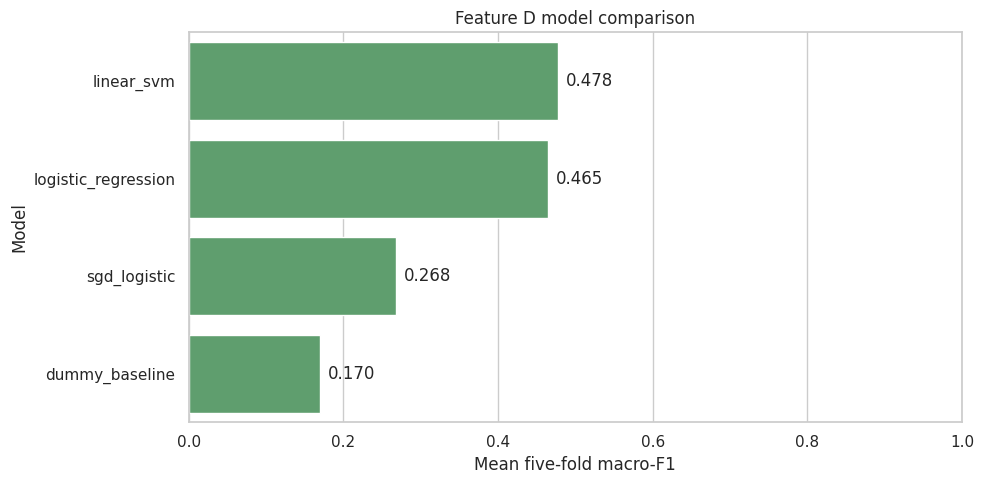

In [11]:
comparison = compare_models(X_train, y_train, folds=5)
display(comparison.style.format({
    'cv_macro_f1_mean': '{:.3f}', 'cv_macro_f1_std': '{:.3f}',
    'cv_accuracy_mean': '{:.3f}', 'cv_balanced_accuracy_mean': '{:.3f}',
}))

plt.figure(figsize=(10, 5))
sns.barplot(data=comparison, x='cv_macro_f1_mean', y='model', color='#55A868')
plt.xlim(0, 1); plt.xlabel('Mean five-fold macro-F1'); plt.ylabel('Model')
plt.title('Feature D model comparison')
for i, row in comparison.iterrows():
    plt.text(row['cv_macro_f1_mean'] + .01, i, f"{row['cv_macro_f1_mean']:.3f}", va='center')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'model_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

## 7. Fine-tuning and final selection

Tune regularization strength for logistic regression and Linear SVM. Selection uses cross-validated training macro-F1 only; the held-out test set remains untouched until the final evaluation.

In [12]:
searches = tune_linear_candidates(X_train, y_train, folds=5)
tuning = pd.DataFrame([
    {'model': name, 'best_cv_macro_f1': search.best_score_, 'best_parameters': search.best_params_}
    for name, search in searches.items()
]).sort_values('best_cv_macro_f1', ascending=False)
display(tuning)

winner_name, winner_search = choose_search(searches)
best_model = winner_search.best_estimator_
print('Selected model:', winner_name)
print('Selected parameters:', winner_search.best_params_)
print('Selection CV macro-F1:', round(winner_search.best_score_, 4))

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,model,best_cv_macro_f1,best_parameters
1,linear_svm,0.483233,{'classifier__C': 2.0}
0,logistic_regression,0.476631,{'classifier__C': 2.0}


Selected model: linear_svm
Selected parameters: {'classifier__C': 2.0}
Selection CV macro-F1: 0.4832


## 8. Final held-out evaluation

Evaluate once on the untouched 20% test set. In addition to accuracy and macro-F1, report ordinal errors: predicting an adjacent tier is less serious than confusing `budget` with `premium`.

,test_value
accuracy,0.582278
macro_f1,0.584020
mean_absolute_tier_error,0.525316
severe_error_rate,0.107595


,precision,recall,f1-score,support
budget,0.568966,0.589286,0.578947,56.000000
mid_range,0.551724,0.581818,0.566372,55.000000
premium,0.642857,0.574468,0.606742,47.000000
accuracy,0.582278,0.582278,0.582278,0.582278
macro avg,0.587849,0.581857,0.584020,158.000000
weighted avg,0.584944,0.582278,0.582838,158.000000


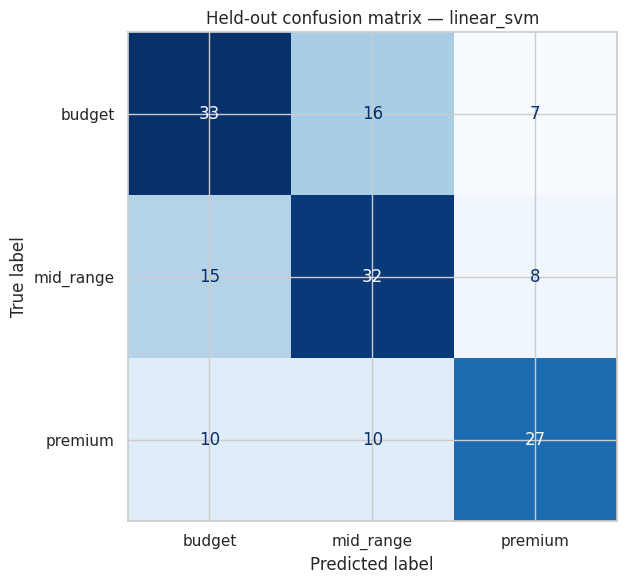

In [13]:
test_metrics, test_report, test_matrix = evaluate(best_model, X_test, y_test)
display(pd.Series(test_metrics, name='test_value').to_frame())
display(test_report)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(test_matrix, display_labels=TIER_ORDER).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f"Held-out confusion matrix — {winner_name}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'test_confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()

In [14]:
test_results = test[['asin', 'title', 'search_keyword', 'price_numeric', 'label_currency', 'price_tier']].copy()
test_results['predicted_tier'] = best_model.predict(X_test)
test_results['correct'] = test_results['price_tier'].eq(test_results['predicted_tier'])

print('Misclassified examples for qualitative error analysis:')
display(test_results[~test_results['correct']].head(25))

category_scores = []
for category, part in test_results.groupby('search_keyword'):
    category_scores.append({
        'search_keyword': category, 'test_products': len(part),
        'macro_f1': f1_score(part['price_tier'], part['predicted_tier'], labels=TIER_ORDER, average='macro', zero_division=0),
    })
category_scores = pd.DataFrame(category_scores).sort_values(['macro_f1', 'test_products'])
display(category_scores)

Misclassified examples for qualitative error analysis:


,asin,title,search_keyword,price_numeric,label_currency,price_tier,predicted_tier,correct
492,B0DLCG65B5,DYSANKY Insulated Water Bottle w/Straw Lid & P...,water bottle,26.99,USD,premium,mid_range,False
846,B07NTSWK41,Fender CD-60 Dreadnought Acoustic Guitar - Sun...,yamaha accoustic guitar,194.99,USD,budget,mid_range,False
249,B0DNMLK6SC,"Bitvae ADA Accepted Electric Toothbrush, 60-Da...",electric toothbrush,16.12,USD,budget,mid_range,False
777,B0CRTQ3J5D,suoso Sports Polarized Sunglasses for Men: Wom...,sunglasses,20.39,USD,premium,budget,False
143,B0FG7XJWLM,"CHARYJOD LED Desk Lamp for Office Home, Height...",desk lamp LED,29.99,USD,mid_range,budget,False
663,B07BKLXNC7,Skechers Women's Summits Quick Getaway,sneakers,32.59,USD,budget,mid_range,False
212,B09MZTP44L,Instant Pot 6 Qt 9-in-1 Electric Pressure Cook...,instant pot,119.99,USD,mid_range,budget,False
180,B0GF1GYKW5,"Syrinx LED Desk Lamp for Home Office, 18W 2000...",desk lamp LED,29.99,USD,mid_range,premium,False
582,B06XWG4X6L,Amazon Essentials Men's Slim Fit Crewneck Unde...,t-shirt,16.90,USD,mid_range,premium,False
101,B0BTY4NCK7,"Mini Portable Charger Power Bank for iPhone,52...",portable charger,9.99,USD,budget,premium,False


,search_keyword,test_products,macro_f1
19,portable charger,3,0.166667
10,gaming chair,8,0.190476
22,sunglasses,11,0.195286
0,DSLR camera,3,0.266667
12,instant pot,3,0.266667
20,smartwatch,3,0.266667
26,wireless earbuds,3,0.266667
2,air purifier,2,0.333333
3,backpack,3,0.333333
5,budget laptop,3,0.333333


### Evaluation interpretation

A suitable final model should clearly beat the dummy baseline, have reasonably similar recall across all three tiers, and keep the severe-error rate low. Review the misclassified examples: products near learned thresholds are inherently harder than products at the extremes. Category-level scores are diagnostic only because some test categories contain few products.

## 9. Model interpretation

For a linear winner, positive coefficients show which non-price attributes push predictions toward each tier. They are associations, not causal effects. Verify that no extracted feature contains price columns.

,tier,feature,coefficient
0,budget,categorical__brand_Oster,1.097943
1,budget,categorical__category_breadcrumb_Cell Phones &...,1.056326
2,budget,categorical__brand_casmilee,1.008979
3,budget,categorical__brand_Taja,1.005350
4,budget,text__small,0.999068
5,budget,categorical__category_breadcrumb_Electronics >...,0.998173
6,budget,categorical__brand_Redragon,0.932025
7,budget,categorical__brand_LOVEVOOK,0.859045
8,budget,categorical__availability_This item cannot be ...,0.834653
9,budget,categorical__brand_Tastyle,0.833269


/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:123: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  self._figure.tight_layout(*args, **kwargs)


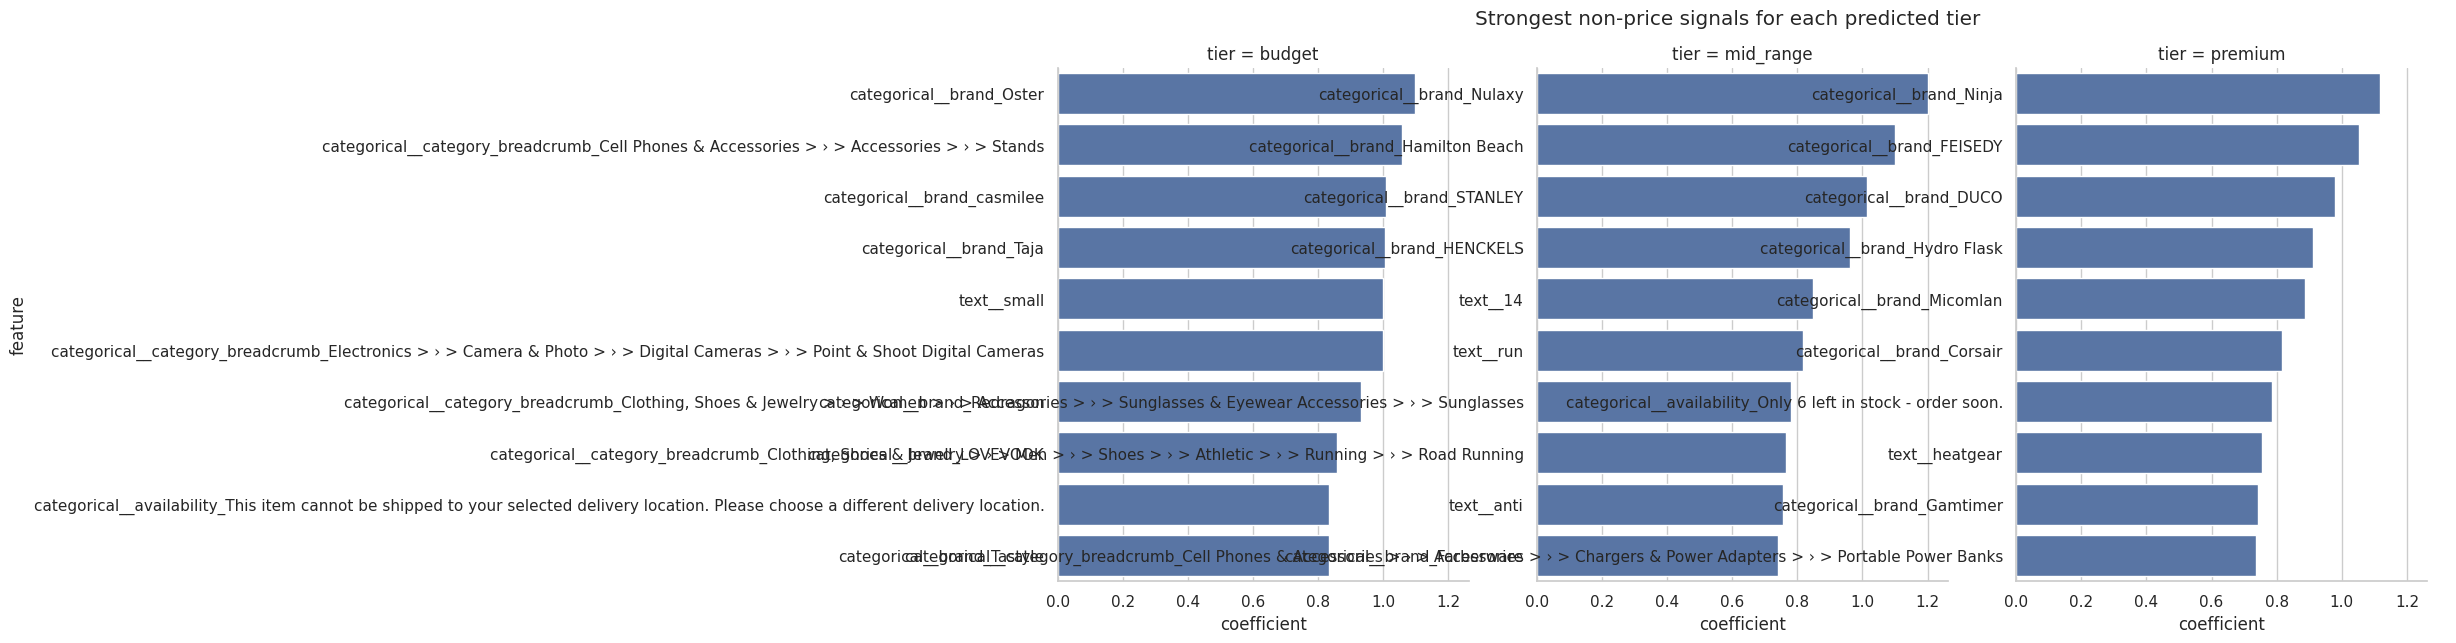

In [15]:
important = top_linear_features(best_model, top_n=15)
if important.empty:
    print('The selected model does not expose linear coefficients.')
else:
    display(important)
    chart = important.groupby('tier').head(10).copy()
    g = sns.catplot(data=chart, x='coefficient', y='feature', col='tier', kind='bar', sharey=False, height=6, aspect=.8)
    g.fig.suptitle('Strongest non-price signals for each predicted tier', y=1.03)
    g.savefig(OUTPUT_DIR / 'top_model_features.png', dpi=160, bbox_inches='tight')
    plt.show()

## 10. Refit on all labelled products and predict every product

After evaluation is complete, relearn tier rules on all 786 priced products, refit the selected configuration, and predict all products—including rows whose price is missing. Missing-price rows receive a prediction but never a fabricated training label.

In [16]:
final_model, final_rules, all_predictions = refit_for_deployment(best_model, prepared)
final_metrics = {
    **test_metrics,
    'selected_model': winner_name,
    'selected_parameters': winner_search.best_params_,
    'selection_cv_macro_f1': float(winner_search.best_score_),
    'labelled_products': int(prepared['label_eligible'].sum()),
    'missing_price_prediction_products': int(prepared['price_numeric'].isna().sum()),
    'tier_definition': 'category-and-currency-relative unique-price 33rd/67th percentiles',
}

save_artifacts(OUTPUT_DIR, final_model, final_rules, all_predictions, final_metrics)
display(all_predictions.head())
print('Predictions for products with missing observed price:')
display(all_predictions[all_predictions['price_was_missing']].head(25))
print('Saved files:')
for path in sorted(OUTPUT_DIR.glob('*')):
    print('-', path.name)

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,asin,title,search_keyword,observed_price,observed_currency,price_was_missing,predicted_price_tier,known_price_tier
0,B0H9LHWBDK,"Wireless Earbuds, 2026 Bluetooth 5.4 Headphone...",wireless earbuds,190.39,SEK,False,budget,budget
1,B0HBWW3958,"Wireless Earbuds, Bluetooth 5.3 Headphones HiF...",wireless earbuds,190.30,SEK,False,budget,budget
2,B0H3NTRWCL,"AI Translation Earbuds Real Time, 134 Language...",wireless earbuds,190.39,SEK,False,budget,budget
3,B0H7R1LD7B,"HAOYUYAN Wireless Earbuds, Sports Bluetooth He...",wireless earbuds,228.40,SEK,False,premium,premium
4,B0G7H6K1WN,"Wireless Earbuds,Bluetooth 5.4 Ear buds,Sport ...",wireless earbuds,161.82,SEK,False,budget,budget


Predictions for products with missing observed price:


,asin,title,search_keyword,observed_price,observed_currency,price_was_missing,predicted_price_tier,known_price_tier
14,B0D9R4GYTN,Sony WF-C510 Truly Wireless Bluetooth Earbud H...,wireless earbuds,NaN,<NA>,True,premium,<NA>
58,B09LK1P1RD,Logitech MX Mechanical Wireless Illuminated Ke...,mechanical keyboard,NaN,<NA>,True,premium,<NA>
106,B09J4NS86D,"Mini Portable Charger for iWatch 12000mAh, Pow...",portable charger,NaN,<NA>,True,budget,<NA>
184,B0BGPF71Q6,LEVOIT Smart Air Purifier for Home Large Room ...,air purifier,NaN,<NA>,True,budget,<NA>
191,B004VGIGVY,GermGuardian HEPA Air Purifier - Large Room Ai...,air purifier,NaN,<NA>,True,mid_range,<NA>
192,B01728NLRG,"COWAY Air Purifier for Home Up to 1,748ft², HE...",air purifier,NaN,<NA>,True,mid_range,<NA>
194,B08KPJ76RR,BLUEAIR Blue Pure 511i Max Smart Air Purifier ...,air purifier,NaN,<NA>,True,mid_range,<NA>
220,B09LD8VFS1,Philips Sonicare 4100 Rechargeable Electric To...,electric toothbrush,NaN,<NA>,True,mid_range,<NA>
222,B09LD8T445,Philips Sonicare 4100 Rechargeable Electric To...,electric toothbrush,NaN,<NA>,True,mid_range,<NA>
223,B0B5HRWH1S,Oral-B iO Series 3 Limited Deep Clean Recharge...,electric toothbrush,NaN,<NA>,True,premium,<NA>


Saved files:
- attribute_relationships_by_tier.png
- missing_values_before.png
- model_comparison.png
- numeric_relationship_heatmap.png
- price_tier_metrics.json
- price_tier_model.joblib
- price_tier_predictions.csv
- price_tier_rules.csv
- test_confusion_matrix.png
- tier_label_distribution.png
- top_model_features.png


## 11. Final requirement checklist

- [x] Missing values audited and handled without inventing target prices.
- [x] Duplicate and invalid values handled before modelling.
- [x] Price used only to define/check labels, never as a predictor.
- [x] Mixed currencies kept separate during label construction.
- [x] Text, brand, category, rating, review count, rank, availability, and missingness signals used.
- [x] EDA and label distributions visualized and interpreted.
- [x] Baseline plus three suitable trained models compared.
- [x] Two strongest linear candidates fine-tuned.
- [x] Final selection based on cross-validated macro-F1.
- [x] Final model evaluated on an untouched test set.
- [x] Confusion matrix, ordinal error measures, error examples, and feature interpretation included.
- [x] Final model, label rules, metrics, and predictions saved to Google Drive.